# Feature-agnostic activation steering for an encoder–decoder model

This notebook tests whether **one shared `google/flan-t5-small` model** can be controlled by multiple activation directions during the same decoder pass.

Initial features:

- `formality`: learned from paired GYAFC informal → formal targets.
- `detoxification`: learned from paired ParaDetox toxic → neutral targets.

The design is deliberately feature-agnostic. Every feature is data plus metadata: a key, paired negative/positive targets, a selected decoder layer, a direction, and a coefficient scale. The steering engine accepts a mapping such as `{"formality": alpha, "detoxification": beta}`. A coefficient of zero is the explicit **off switch**. Adding another feature later does not require changing the hook implementation.

## Why decoder directions?

For every pair, the encoder receives the **same source message and fixed rewrite instruction**. We teacher-force two possible decoder targets: the negative side and positive side of the feature. Their paired decoder-state difference therefore measures how the output representation changes while the source context remains fixed.

In [2]:
from contextlib import ExitStack
from dataclasses import dataclass
from pathlib import Path
import json
import math
import time

from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

from secondthought.evaluation import (
    DetoxifyToxicityScorer,
    SentenceTransformerSimilarityScorer,
    evaluate_records,
)
from secondthought.steering_rewriter import BASE_REWRITE_PROMPT, make_steering_hook

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()),
    Path.cwd(),
)
ARTIFACT_DIRECTORY = PROJECT_ROOT / "steering_experimentation" / "artifacts"
RESULT_DIRECTORY = PROJECT_ROOT / "testing" / "results"
ARTIFACT_DIRECTORY.mkdir(parents=True, exist_ok=True)
RESULT_DIRECTORY.mkdir(parents=True, exist_ok=True)

MODEL_ID = "google/flan-t5-small"
GYAFC_ROOT = Path("/Users/nandanprince/Downloads/GYAFC_Corpus")
PARADETOX_ID = "s-nlp/paradetox"
TEST_PATH = PROJECT_ROOT / "data" / "workplace_eval" / "input.jsonl"

SEED = 42
EXTRACTION_PAIRS = 2_000
HELDOUT_PAIRS = 500
BATCH_SIZE = 32
MAX_SOURCE_LENGTH = 192
MAX_TARGET_LENGTH = 96
ALPHAS = [0.0, 1.0, 2.0]
BETAS = [0.0, 1.0, 2.0]

ARTIFACT_PATH = ARTIFACT_DIRECTORY / "flan_t5_small_feature_directions.pt"
LAYER_RESULTS_PATH = RESULT_DIRECTORY / "t5_feature_layer_results.csv"
PREDICTIONS_PATH = RESULT_DIRECTORY / "t5_mixed_steering_predictions.csv"
EVALUATED_PATH = RESULT_DIRECTORY / "t5_mixed_steering_evaluated.csv"
SUMMARY_PATH = RESULT_DIRECTORY / "t5_mixed_steering_summary.csv"

device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID).to(device)
model.eval()
print({
    "model": MODEL_ID,
    "device": str(device),
    "decoder_layers": model.config.num_decoder_layers,
    "hidden_size": model.config.d_model,
})

ModuleNotFoundError: No module named 'datasets'

## 1. Register paired feature datasets

The extraction algorithm does not know what “formality” or “detoxification” means. It only consumes the same four-column schema:

- `source`: encoder input message;
- `negative`: target on the feature’s negative side;
- `positive`: target on the feature’s positive side;
- `feature`: stable registry key.

In [2]:
@dataclass(frozen=True)
class FeatureDataset:
    key: str
    negative_label: str
    positive_label: str
    pairs: pd.DataFrame


def normalize_text(text):
    return " ".join(str(text).split()).casefold()


def prepare_pairs(frame, source_column, negative_column, positive_column, feature):
    result = frame[[source_column, negative_column, positive_column]].rename(
        columns={
            source_column: "source",
            negative_column: "negative",
            positive_column: "positive",
        }
    ).copy()
    for column in ("source", "negative", "positive"):
        result[column] = result[column].fillna("").astype(str).str.strip()
    result = result.loc[(result[["source", "negative", "positive"]] != "").all(axis=1)]
    result["negative_key"] = result["negative"].map(normalize_text)
    result["positive_key"] = result["positive"].map(normalize_text)
    result = result.loc[result["negative_key"] != result["positive_key"]]
    result = result.drop_duplicates(["negative_key", "positive_key"])
    result = result.sample(frac=1, random_state=SEED).drop_duplicates("negative_key")
    result["feature"] = feature
    return result.reset_index(drop=True)


gyafc_parts = []
for domain in ("Entertainment_Music", "Family_Relationships"):
    informal = (GYAFC_ROOT / domain / "train" / "informal").read_text().splitlines()
    formal = (GYAFC_ROOT / domain / "train" / "formal").read_text().splitlines()
    if len(informal) != len(formal):
        raise ValueError(f"Unaligned GYAFC train files for {domain}")
    gyafc_parts.append(pd.DataFrame({"informal": informal, "formal": formal}))
gyafc_raw = pd.concat(gyafc_parts, ignore_index=True)
formality_pairs = prepare_pairs(
    gyafc_raw.assign(source=gyafc_raw["informal"]),
    "source", "informal", "formal", "formality",
)

paradetox_raw = load_dataset(PARADETOX_ID, split="train")
paradetox_frame = paradetox_raw.select_columns(
    ["en_toxic_comment", "en_neutral_comment"]
).to_pandas()
detox_pairs = prepare_pairs(
    paradetox_frame.assign(source=paradetox_frame["en_toxic_comment"]),
    "source", "en_toxic_comment", "en_neutral_comment", "detoxification",
)

FEATURE_DATASETS = {
    "formality": FeatureDataset(
        "formality", "informal", "formal", formality_pairs
    ),
    "detoxification": FeatureDataset(
        "detoxification", "toxic", "neutral", detox_pairs
    ),
}

for key, spec in FEATURE_DATASETS.items():
    print(key, len(spec.pairs), "usable pairs")

Using the latest cached version of the dataset since s-nlp/paradetox couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /Users/nandanprince/.cache/huggingface/datasets/s-nlp___paradetox/default/0.0.0/958b799a4c3a7c16463632465aaaa8ad083235a8 (last modified on Tue Oct  6 22:20:28 2026).


formality 99278 usable pairs
detoxification 11838 usable pairs


In [3]:
def deterministic_split(frame):
    required = EXTRACTION_PAIRS + HELDOUT_PAIRS
    if len(frame) < required:
        raise ValueError(f"Need {required:,} pairs; found {len(frame):,}")
    positions = np.random.default_rng(SEED).permutation(len(frame))[:required]
    extraction = frame.iloc[positions[:EXTRACTION_PAIRS]].reset_index(drop=True)
    heldout = frame.iloc[positions[EXTRACTION_PAIRS:]].reset_index(drop=True)
    return extraction, heldout


feature_splits = {
    key: deterministic_split(spec.pairs)
    for key, spec in FEATURE_DATASETS.items()
}
pd.DataFrame(
    {
        key: {"extraction": len(parts[0]), "heldout": len(parts[1])}
        for key, parts in feature_splits.items()
    }
).T

,extraction,heldout
formality,2000,500
detoxification,2000,500


## 2. Extract paired decoder differences at every layer

For each source message, the model sees the same encoder prompt twice. Only the teacher-forced decoder target changes. At hidden-state index `d`, the paired difference is:

$$\Delta_{i,d} = h_{i,d}^{positive} - h_{i,d}^{negative}$$

We compare mean pooling and final-token pooling. Hidden-state index 0 is the decoder embedding output; index `d+1` corresponds to hookable decoder block `d`.

In [4]:
def mean_pool(hidden, mask):
    expanded = mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * expanded).sum(dim=1) / expanded.sum(dim=1).clamp_min(1)


def final_token_pool(hidden, mask):
    positions = mask.sum(dim=1) - 1
    batch = torch.arange(hidden.shape[0], device=hidden.device)
    return hidden[batch, positions]


def rewrite_prompt(message):
    return f"{BASE_REWRITE_PROMPT}\n\nMessage:\n{message}"


def collect_decoder_deltas(frame, label):
    pair_count = len(frame)
    depth_count = model.config.num_decoder_layers + 1
    deltas = torch.empty(
        (2, pair_count, depth_count, model.config.d_model), dtype=torch.float16
    )
    started = time.perf_counter()

    for batch_number, start in enumerate(range(0, pair_count, BATCH_SIZE), 1):
        stop = min(start + BATCH_SIZE, pair_count)
        batch = frame.iloc[start:stop]
        size = len(batch)
        sources = [rewrite_prompt(text) for text in batch["source"]]
        targets = batch["negative"].tolist() + batch["positive"].tolist()
        encoder_texts = sources + sources

        encoder = tokenizer(
            encoder_texts,
            padding=True,
            truncation=True,
            max_length=MAX_SOURCE_LENGTH,
            return_tensors="pt",
        ).to(device)
        target = tokenizer(
            text_target=targets,
            padding=True,
            truncation=True,
            max_length=MAX_TARGET_LENGTH,
            return_tensors="pt",
        ).to(device)
        labels = target["input_ids"].clone()
        labels[labels == tokenizer.pad_token_id] = -100

        with torch.inference_mode():
            outputs = model(
                **encoder,
                labels=labels,
                decoder_attention_mask=target["attention_mask"],
                output_hidden_states=True,
                use_cache=False,
                return_dict=True,
            )
        for depth, hidden in enumerate(outputs.decoder_hidden_states):
            mean = mean_pool(hidden, target["attention_mask"])
            final = final_token_pool(hidden, target["attention_mask"])
            deltas[0, start:stop, depth] = (
                mean[size:] - mean[:size]
            ).cpu().to(torch.float16)
            deltas[1, start:stop, depth] = (
                final[size:] - final[:size]
            ).cpu().to(torch.float16)

        if batch_number == 1 or batch_number % 20 == 0 or stop == pair_count:
            print(
                f"{label}: {stop:,}/{pair_count:,} pairs · "
                f"{time.perf_counter() - started:.1f}s"
            )
    return deltas


feature_deltas = {}
for feature_key, (extraction, heldout) in feature_splits.items():
    feature_deltas[feature_key] = {
        "extraction": collect_decoder_deltas(extraction, f"{feature_key}/extraction"),
        "heldout": collect_decoder_deltas(heldout, f"{feature_key}/heldout"),
    }

formality/extraction: 32/2,000 pairs · 0.4s


formality/extraction: 640/2,000 pairs · 5.7s


formality/extraction: 1,280/2,000 pairs · 10.3s


formality/extraction: 1,920/2,000 pairs · 14.6s


formality/extraction: 2,000/2,000 pairs · 15.2s


...

detoxification/extraction: 640/2,000 pairs · 3.7s


detoxification/extraction: 1,280/2,000 pairs · 7.5s


detoxification/extraction: 1,920/2,000 pairs · 11.5s


detoxification/extraction: 2,000/2,000 pairs · 12.5s
detoxification/heldout: 32/500 pairs · 0.2s


detoxification/heldout: 500/500 pairs · 3.5s


## 3. Evaluate layer-wise geometry and select one candidate per feature

Metrics:

- **Held-out ordering accuracy:** fraction of unseen positive-minus-negative pairs whose projection is positive; chance is 50%.
- **Projection effect size:** mean divided by standard deviation of held-out paired projections.
- **Split-half cosine:** agreement between directions estimated from two disjoint extraction halves.

Candidate selection is restricted to hookable decoder outputs and uses held-out ordering first, then effect size. This is exploratory selection; a future production pipeline should add a third untouched validation split.

In [5]:
pooling_names = ["mean", "final_token"]
layer_rows = []
candidate_directions = {}

for feature_key, split_deltas in feature_deltas.items():
    extraction = split_deltas["extraction"].float()
    heldout = split_deltas["heldout"].float()
    for pooling_index, pooling in enumerate(pooling_names):
        for hidden_state_index in range(extraction.shape[2]):
            extraction_at_layer = extraction[pooling_index, :, hidden_state_index]
            heldout_at_layer = heldout[pooling_index, :, hidden_state_index]
            raw_direction = extraction_at_layer.mean(dim=0)
            unit_direction = raw_direction / raw_direction.norm().clamp_min(1e-12)
            heldout_projection = heldout_at_layer @ unit_direction
            half = len(extraction_at_layer) // 2
            half_a = extraction_at_layer[:half].mean(dim=0)
            half_b = extraction_at_layer[half:].mean(dim=0)
            split_half_cosine = torch.nn.functional.cosine_similarity(
                half_a, half_b, dim=0
            ).item()
            layer_rows.append({
                "feature": feature_key,
                "pooling": pooling,
                "hidden_state_index": hidden_state_index,
                "layer_index": hidden_state_index - 1,
                "raw_direction_norm": raw_direction.norm().item(),
                "heldout_ordering_accuracy": (heldout_projection > 0).float().mean().item(),
                "projection_effect_size": (
                    heldout_projection.mean() / heldout_projection.std().clamp_min(1e-12)
                ).item(),
                "split_half_cosine": split_half_cosine,
            })
            candidate_directions[(feature_key, pooling, hidden_state_index)] = raw_direction.cpu()

layer_results = pd.DataFrame(layer_rows)
layer_results.to_csv(LAYER_RESULTS_PATH, index=False)

hookable = layer_results.query("hidden_state_index >= 1").copy()
selected_rows = (
    hookable.sort_values(
        ["feature", "heldout_ordering_accuracy", "projection_effect_size"],
        ascending=[True, False, False],
    )
    .groupby("feature", as_index=False)
    .head(1)
    .reset_index(drop=True)
)
display(selected_rows.round(4))
print("Saved:", LAYER_RESULTS_PATH)

,feature,pooling,hidden_state_index,layer_index,raw_direction_norm,heldout_ordering_accuracy,projection_effect_size,split_half_cosine
0,detoxification,mean,3,2,280.8613,0.998,1.0255,0.9995
1,formality,mean,7,6,509.2732,0.998,1.9926,0.9983


Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_feature_layer_results.csv


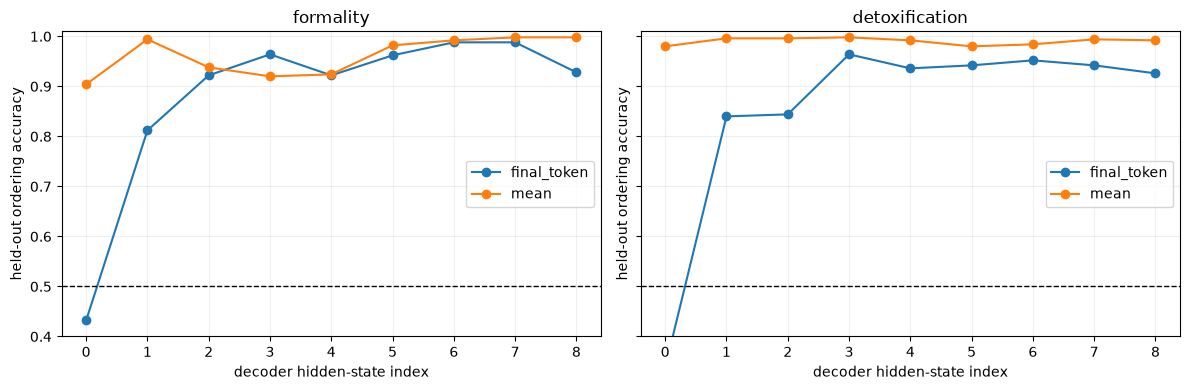

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, feature_key in zip(axes, FEATURE_DATASETS):
    subset = layer_results.query("feature == @feature_key")
    for pooling, group in subset.groupby("pooling"):
        ax.plot(
            group["hidden_state_index"],
            group["heldout_ordering_accuracy"],
            marker="o",
            label=pooling,
        )
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=feature_key,
        xlabel="decoder hidden-state index",
        ylabel="held-out ordering accuracy",
        ylim=(0.4, 1.01),
    )
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Save a model-bound, extensible feature artifact

Each direction is meaningful only for this exact checkpoint and intervention site. The runtime iterates the `features` mapping, so future features can be appended with the same fields.

In [7]:
features = {}
for row in selected_rows.itertuples(index=False):
    direction = candidate_directions[(row.feature, row.pooling, row.hidden_state_index)]
    features[row.feature] = {
        "negative_label": FEATURE_DATASETS[row.feature].negative_label,
        "positive_label": FEATURE_DATASETS[row.feature].positive_label,
        "layer_index": int(row.layer_index),
        "hidden_state_index": int(row.hidden_state_index),
        "pooling": row.pooling,
        "direction": direction,
        "coefficient_scale": 1.0,
        "raw_direction_norm": float(row.raw_direction_norm),
        "heldout_ordering_accuracy": float(row.heldout_ordering_accuracy),
        "projection_effect_size": float(row.projection_effect_size),
        "split_half_cosine": float(row.split_half_cosine),
    }

artifact = {
    "format_version": 1,
    "model_id": MODEL_ID,
    "architecture": "encoder_decoder",
    "intervention_site": "decoder_blocks",
    "base_prompt": BASE_REWRITE_PROMPT,
    "seed": SEED,
    "extraction_pairs_per_feature": EXTRACTION_PAIRS,
    "heldout_pairs_per_feature": HELDOUT_PAIRS,
    "features": features,
}
torch.save(artifact, ARTIFACT_PATH)
print("Saved:", ARTIFACT_PATH)
display(pd.DataFrame(features).T.drop(columns="direction").round(4))

Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/steering_experimentation/artifacts/flan_t5_small_feature_directions.pt


,negative_label,positive_label,layer_index,hidden_state_index,pooling,coefficient_scale,raw_direction_norm,heldout_ordering_accuracy,projection_effect_size,split_half_cosine
detoxification,toxic,neutral,2,3,mean,1.0,280.861267,0.998,1.025492,0.999547
formality,informal,formal,6,7,mean,1.0,509.273163,0.998,1.992617,0.998307


## 5. Verify independent on/off controls

All enabled feature hooks are registered for the same decoder pass. If two features select the same layer, their shifts are additive; if they select different layers, the earlier shift propagates into the later layer. The engine itself is unaware of feature semantics.

In [8]:
decoder_blocks = model.decoder.block


def effective_controls(alpha, beta, formality_on=True, detoxification_on=True):
    return {
        "formality": float(alpha) if formality_on else 0.0,
        "detoxification": float(beta) if detoxification_on else 0.0,
    }


def generate_batch(messages, controls):
    prompts = [rewrite_prompt(message) for message in messages]
    encoded = tokenizer(
        prompts,
        padding=True,
        truncation=True,
        max_length=MAX_SOURCE_LENGTH,
        return_tensors="pt",
    ).to(device)
    with ExitStack() as stack:
        for feature_key, coefficient in controls.items():
            if float(coefficient) == 0:
                continue
            metadata = features[feature_key]
            handle = decoder_blocks[metadata["layer_index"]].register_forward_hook(
                make_steering_hook(metadata["direction"], float(coefficient))
            )
            stack.callback(handle.remove)
        with torch.inference_mode():
            output_ids = model.generate(
                **encoded,
                max_new_tokens=80,
                num_beams=4,
                do_sample=False,
            )
    return tokenizer.batch_decode(output_ids, skip_special_tokens=True)


control_demo = "This lazy crap has cost us 2 hours already. Restart the scanner and call Priya if it fails again."
demo_rows = []
for label, controls in {
    "both off": effective_controls(2, 2, False, False),
    "formality only": effective_controls(1, 2, True, False),
    "detoxification only": effective_controls(2, 1, False, True),
    "both on": effective_controls(1, 1, True, True),
}.items():
    demo_rows.append({
        "condition": label,
        "controls": controls,
        "generated": generate_batch([control_demo], controls)[0],
    })
pd.DataFrame(demo_rows)

,condition,controls,generated
0,both off,"{'formality': 0.0, 'detoxification': 0.0}",This lazy crap has cost us 2 hours already. Re...
1,formality only,"{'formality': 1.0, 'detoxification': 0.0}",This lazy crap has cost us 2 hours already. Re...
2,detoxification only,"{'formality': 0.0, 'detoxification': 1.0}",This lazy crap has cost us 2 hours already. Re...
3,both on,"{'formality': 1.0, 'detoxification': 1.0}",This lazy crap has cost us 2 hours already. Re...


## 6. Run the shared 35-message test set

The 3×3 grid reproduces the decoder-only experiment: `0` is off, positive values move toward the learned positive feature side, and mixed cells activate both directions simultaneously.

In [9]:
with TEST_PATH.open() as handle:
    test_rows = [json.loads(line) for line in handle if line.strip()]
test_messages = [row["original_text"] for row in test_rows]

prediction_rows = []
started = time.perf_counter()
for alpha in ALPHAS:
    for beta in BETAS:
        controls = effective_controls(alpha, beta)
        generated = generate_batch(test_messages, controls)
        for source, output in zip(test_rows, generated, strict=True):
            prediction_rows.append({
                "id": source["id"],
                "model_name": "flan_t5_small_mixed_steering",
                "alpha": alpha,
                "beta": beta,
                "formality_enabled": alpha != 0,
                "detoxification_enabled": beta != 0,
                "original_text": source["original_text"],
                "generated": output.strip(),
            })
        print(
            f"alpha={alpha:.1f}, beta={beta:.1f} complete · "
            f"{time.perf_counter() - started:.1f}s"
        )

predictions = pd.DataFrame(prediction_rows)
predictions.to_csv(PREDICTIONS_PATH, index=False)
print("Saved:", PREDICTIONS_PATH, "rows:", len(predictions))
display(predictions.head())

alpha=0.0, beta=0.0 complete · 4.8s


alpha=0.0, beta=1.0 complete · 7.6s


alpha=0.0, beta=2.0 complete · 8.5s


alpha=1.0, beta=0.0 complete · 11.2s


alpha=1.0, beta=1.0 complete · 12.2s


alpha=1.0, beta=2.0 complete · 13.2s


alpha=2.0, beta=0.0 complete · 14.2s


alpha=2.0, beta=1.0 complete · 15.2s


alpha=2.0, beta=2.0 complete · 16.1s
Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_mixed_steering_predictions.csv rows: 315


,id,model_name,alpha,beta,formality_enabled,detoxification_enabled,original_text,generated
0,input_001,flan_t5_small_mixed_steering,0.0,0.0,False,False,"Seriously, Maya, this invoice is a damn mess. ...","Message: Seriously, Maya, this invoice is a da..."
1,input_002,flan_t5_small_mixed_steering,0.0,0.0,False,False,You dumped 18 broken laptops on my desk like a...,You dumped 18 broken laptops on my desk like a...
2,input_003,flan_t5_small_mixed_steering,0.0,0.0,False,False,"I'm sick of your bullshit excuses, Daniel. The...","I'm sick of your bullshit excuses, Daniel. The..."
3,input_004,flan_t5_small_mixed_steering,0.0,0.0,False,False,Who the hell sent the boxes to 47 Willow Lane?...,Who the hell sent the boxes to 47 Willow Lane?...
4,input_005,flan_t5_small_mixed_steering,0.0,0.0,False,False,This lazy crap has cost us 2 hours already. Re...,This lazy crap has cost us 2 hours already. Re...


## 7. Evaluate toxicity, semantic similarity, and critical-value preservation

Formality remains pending until a validated independent formality metric is available. Lower output toxicity is better; higher semantic similarity and critical-value recall are better.

In [10]:
records = [
    {"original_text": row.original_text, "rewritten_text": row.generated}
    for row in predictions.itertuples(index=False)
]
toxicity_scorer = DetoxifyToxicityScorer("original", device="cpu")
similarity_scorer = SentenceTransformerSimilarityScorer(
    "sentence-transformers/all-mpnet-base-v2", device="cpu"
)
metrics = evaluate_records(
    records,
    toxicity_scorer=toxicity_scorer,
    similarity_scorer=similarity_scorer,
)
evaluated = pd.concat(
    [predictions.reset_index(drop=True), pd.DataFrame(metrics)], axis=1
)
evaluated.to_csv(EVALUATED_PATH, index=False)

summary = evaluated.groupby(["alpha", "beta"]).agg(
    examples=("id", "size"),
    mean_input_toxicity=("toxicity_original", "mean"),
    mean_output_toxicity=("toxicity_rewritten", "mean"),
    mean_relative_toxicity_reduction=("toxicity_relative_reduction", "mean"),
    mean_semantic_similarity=("semantic_similarity", "mean"),
    critical_values=("critical_value_count", "sum"),
    critical_values_preserved=("critical_value_preserved_count", "sum"),
    unsupported_values=("critical_value_unsupported_count", "sum"),
).reset_index()
summary["critical_value_recall"] = (
    summary["critical_values_preserved"]
    / summary["critical_values"].replace(0, np.nan)
).fillna(1.0)
summary.to_csv(SUMMARY_PATH, index=False)
display(summary.round(4))
print("Saved:", EVALUATED_PATH)
print("Saved:", SUMMARY_PATH)

,alpha,beta,examples,mean_input_toxicity,mean_output_toxicity,mean_relative_toxicity_reduction,mean_semantic_similarity,critical_values,critical_values_preserved,unsupported_values,critical_value_recall
0,0.0,0.0,35,0.6042,0.5649,0.0687,0.9713,45,45,4,1.0000
1,0.0,1.0,35,0.6042,0.5613,0.0992,0.9845,45,44,2,0.9778
2,0.0,2.0,35,0.6042,0.5163,0.1506,0.9851,45,43,0,0.9556
3,1.0,0.0,35,0.6042,0.5142,0.1329,0.9769,45,44,2,0.9778
4,1.0,1.0,35,0.6042,0.5065,0.1483,0.9891,45,44,0,0.9778
5,1.0,2.0,35,0.6042,0.5025,0.1636,0.9885,45,43,0,0.9556
6,2.0,0.0,35,0.6042,0.5320,0.1093,0.9922,45,44,0,0.9778
7,2.0,1.0,35,0.6042,0.5137,0.1345,0.9891,45,44,0,0.9778
8,2.0,2.0,35,0.6042,0.4738,0.1953,0.9849,45,44,0,0.9778


Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_mixed_steering_evaluated.csv
Saved: /Users/nandanprince/Desktop/NLP_project/SecondThought/testing/results/t5_mixed_steering_summary.csv


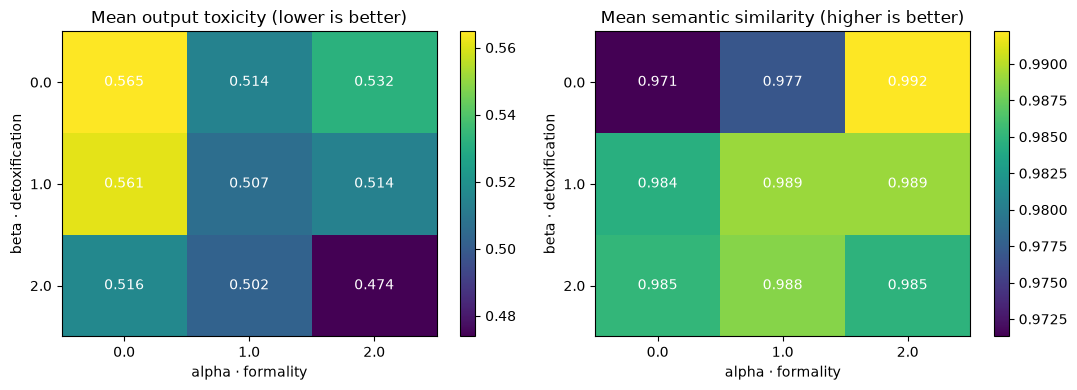

In [11]:
toxicity_grid = summary.pivot(index="beta", columns="alpha", values="mean_output_toxicity")
similarity_grid = summary.pivot(index="beta", columns="alpha", values="mean_semantic_similarity")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, grid, title in [
    (axes[0], toxicity_grid, "Mean output toxicity (lower is better)"),
    (axes[1], similarity_grid, "Mean semantic similarity (higher is better)"),
]:
    image = ax.imshow(grid.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set(xlabel="alpha · formality", ylabel="beta · detoxification", title=title)
    for y in range(grid.shape[0]):
        for x in range(grid.shape[1]):
            ax.text(x, y, f"{grid.iloc[y, x]:.3f}", ha="center", va="center", color="white")
    fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

## Interpretation checklist

1. Geometry above chance shows that a feature is linearly detectable in teacher-forced decoder states; it does not by itself prove causal control.
2. Compare each mixed condition with both corresponding single-feature conditions. A good mixed controller should improve the intended style dimensions without sharply reducing semantic similarity or critical-value recall.
3. Look for monotonic movement as a coefficient increases. A one-off improvement at an extreme value is weak evidence.
4. Inspect individual rows for reversals, omissions, invented facts, refusals, and prompt-like output. Aggregate similarity can miss these failures.
5. The fixed prompt is part of the product baseline. The `(0, 0)` condition measures FLAN-T5’s prompt-only rewrite, not identity copying.

## Results report

### Representation geometry

Both paired concepts are extremely separable in FLAN-T5's teacher-forced decoder states:

| Feature | Selected decoder block | Pooling | Held-out ordering | Effect size | Split-half cosine |
|---|---:|---|---:|---:|---:|
| Formality | 6 | Mean | **99.8%** | 1.993 | 0.9983 |
| Detoxification | 2 | Mean | **99.8%** | 1.025 | 0.9995 |

This establishes stable linear geometry for both datasets in one encoder–decoder checkpoint. It does not establish equally strong causal steering. Because the teacher-forced targets contain different words and lengths, part of this separation can reflect consistent lexical/sequence differences rather than a pure abstract style axis.

### Causal 35-message experiment

| α formality | β detox | Output toxicity ↓ | Semantic similarity ↑ | Critical-value recall ↑ |
|---:|---:|---:|---:|---:|
| 0 | 0 | 0.5649 | 0.9713 | **100.0%** |
| 0 | 2 | 0.5163 | 0.9851 | 95.6% |
| 1 | 1 | 0.5065 | 0.9891 | 97.8% |
| 1 | 2 | 0.5025 | 0.9885 | 95.6% |
| 2 | 0 | 0.5320 | **0.9922** | 97.8% |
| 2 | 2 | **0.4738** | 0.9849 | 97.8% |

The source mean toxicity was 0.6042. Unlike the Qwen experiment, the all-zero FLAN-T5 condition is close to an identity rewrite: it reduces toxicity only modestly, preserves all 45 tracked critical values, and has 0.971 semantic similarity. This makes it a cleaner prompt-only baseline.

Positive beta generally lowers aggregate toxicity, and the strongest tested mixture `(2, 2)` gives the lowest mean toxicity while retaining high semantic similarity and 44/45 critical values. Alpha also changes toxicity, showing that the two learned features are correlated rather than independent. An independent formality metric is still required before attributing alpha's changes specifically to greater formality.

Individual inspection is less impressive than the geometry: relative to `(0, 0)`, beta 1 alone changed only **4/35** outputs, alpha 1 alone changed **4/35**, and even `(2, 2)` changed only **9/35**. A few outputs drop the `Message:` prefix or remove an insult, but most remain exact baseline copies. The current result therefore supports **mild, composable causal control**, not yet a reliable product-grade control surface. The next experiment should calibrate each feature's scale, add negative coefficients, measure formality independently, and explicitly optimize the intervention's response rate.